### 3.2 Train Yolo V8 using Pytorch & Ultralytics Framework
- Setting GPU Environment
- Installing Ultralytics YOLOv8 on Colab
- Download Dataset from Roboflow (previous notebook)
- Train Custom YOLOv8 Detector
- Infer Custom Objects with Saved YOLOv8 (`.pt`)

⚠️⚠️⚠️ *Please open this notebook in Google Colab* by click below link ⚠️⚠️⚠️<br><br>
<a href="https://colab.research.google.com/github/Muhammad-Yunus/Object-Detection-Yolo-OpenCV-Learn/blob/main/Pertemuan%203/3.2 train-yolov8-object-detection-on-custom-dataset.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1.1 Connect GPU Environment

- Click `Connect` button in top right Google Colab notebook,<br>
<img src="https://github.com/Muhammad-Yunus/Object-Detection-Yolo-OpenCV-Learn/blob/main/Pertemuan%203/resource/cl-connect-gpu.png?raw=1" width="250px">
- If connecting process completed, it will turn to something look like this<br>
<img src="https://github.com/Muhammad-Yunus/Object-Detection-Yolo-OpenCV-Learn/blob/main/Pertemuan%203/resource/cl-connect-gpu-success.png?raw=1" width="250px">

- Check GPU connected into Colab environment is active

In [ ]:
!nvidia-smi

Sat Jul 25 13:16:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   56C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os
HOME = os.getcwd()
print(HOME)

/content


## 1.2 Installing Ultralytics YOLOv8 on Colab
- `Ultralytics YOLO` is python library that help simplify YOLO training model in `Pytorch`
- It's wrap `Pytorch` functionality as simple CLI command like we use `Darknet` framework
- More about `Ultralytics YOLO` (https://docs.ultralytics.com/)  

In [ ]:
# Pip install method (recommended)

!pip install -U ultralytics

from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics 8.4.105 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 46.7/112.6 GB disk)


In [ ]:
from ultralytics import YOLO

from IPython.display import display, Image

### 1.2.1 Ultralytics CLI Basics

If you want to train, validate or run inference on models and don't need to make any modifications to the code, using YOLO command line interface is the easiest way to get started. Read more about CLI in [Ultralytics YOLO Docs](https://docs.ultralytics.com/usage/cli/).

```
yolo task=detect    mode=train    model=yolov8n.yaml      args...
          classify       predict        yolov8n-cls.yaml  args...
          segment        val            yolov8n-seg.yaml  args...
                         export         yolov8n.pt        format=onnx  args...
```

## 1.3 Download Dataset from Roboflow (previous notebook)

- Back to `Roboflow` > `Project` > `Versions` menu
- Then click `Download Dataset`<br>
<img src="https://github.com/Muhammad-Yunus/Object-Detection-Yolo-OpenCV-Learn/blob/main/Pertemuan%203/resource/rb-download-dataset.png?raw=1" width="850px">
- Choose `YOLO V8` format and select `Show download code` then click `Continue` <br>
<img src="https://github.com/Muhammad-Yunus/Object-Detection-Yolo-OpenCV-Learn/blob/main/Pertemuan%203/resource/rb-download-format.png?raw=1" width="350px">
- click `Copy` icon to copy roboflow download code<br>
<img src="https://github.com/Muhammad-Yunus/Object-Detection-Yolo-OpenCV-Learn/blob/main/Pertemuan%203/resource/rb-copy-download-code.png?raw=1" width="350px">
- Then replace below code using the copied roboflow download code above,


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="MJegejjkExVgaWSi0WLm")
project = rf.workspace("mohammads-workspace-w5nuu").project("electrical-simbol")
version = project.version(7)
dataset = version.download("yolov8")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Electrical-Simbol-7 in yolov8:: 100%|██████████| 89/89 [00:00<00:00, 7309.30it/s]


## Custom Training
- Don't forget to change `imgsz=` to image size uploaded in Roboflow
- Default `imgsz=320`

In [ ]:
%cd {HOME}

!yolo task=detect mode=train model=yolov8s.pt data={dataset.location}/data.yaml epochs=25 imgsz=640 plots=True

/content
Ultralytics 8.4.105 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Electrical-Simbol-7/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64,

In [ ]:
!ls {HOME}/runs/detect/train/

args.yaml			 labels.jpg	    train_batch46.jpg
BoxF1_curve.png			 results.csv	    train_batch47.jpg
BoxP_curve.png			 results.png	    val_batch0_labels.jpg
BoxPR_curve.png			 train_batch0.jpg   val_batch0_pred.jpg
BoxR_curve.png			 train_batch1.jpg   weights
confusion_matrix_normalized.png  train_batch2.jpg
confusion_matrix.png		 train_batch45.jpg


- Check Results Plot

/content


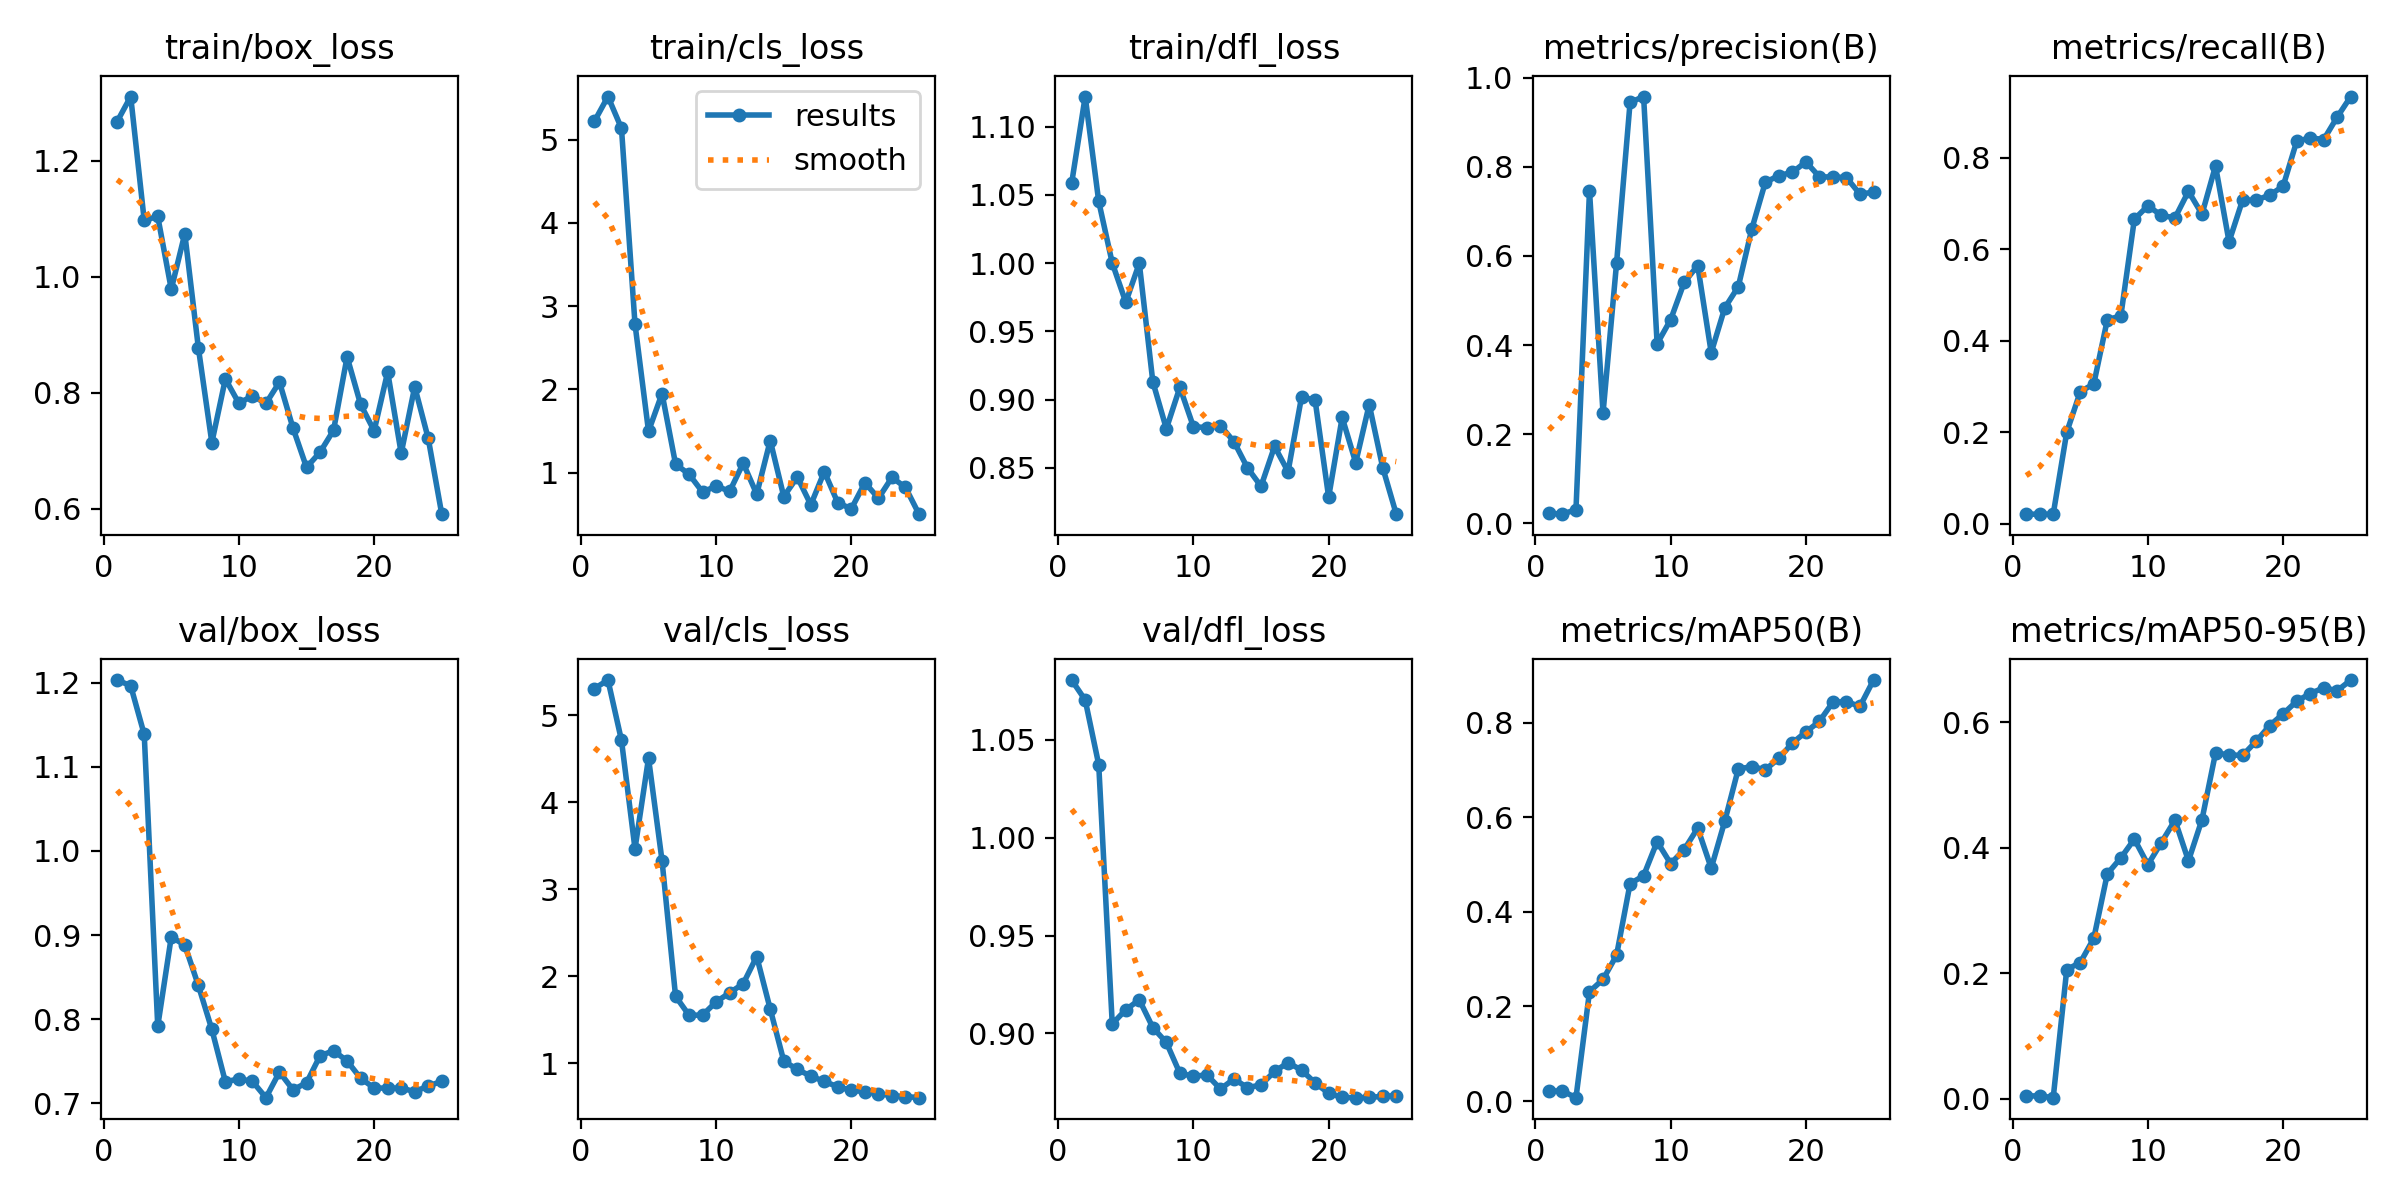

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train/results.png', width=600)

/content


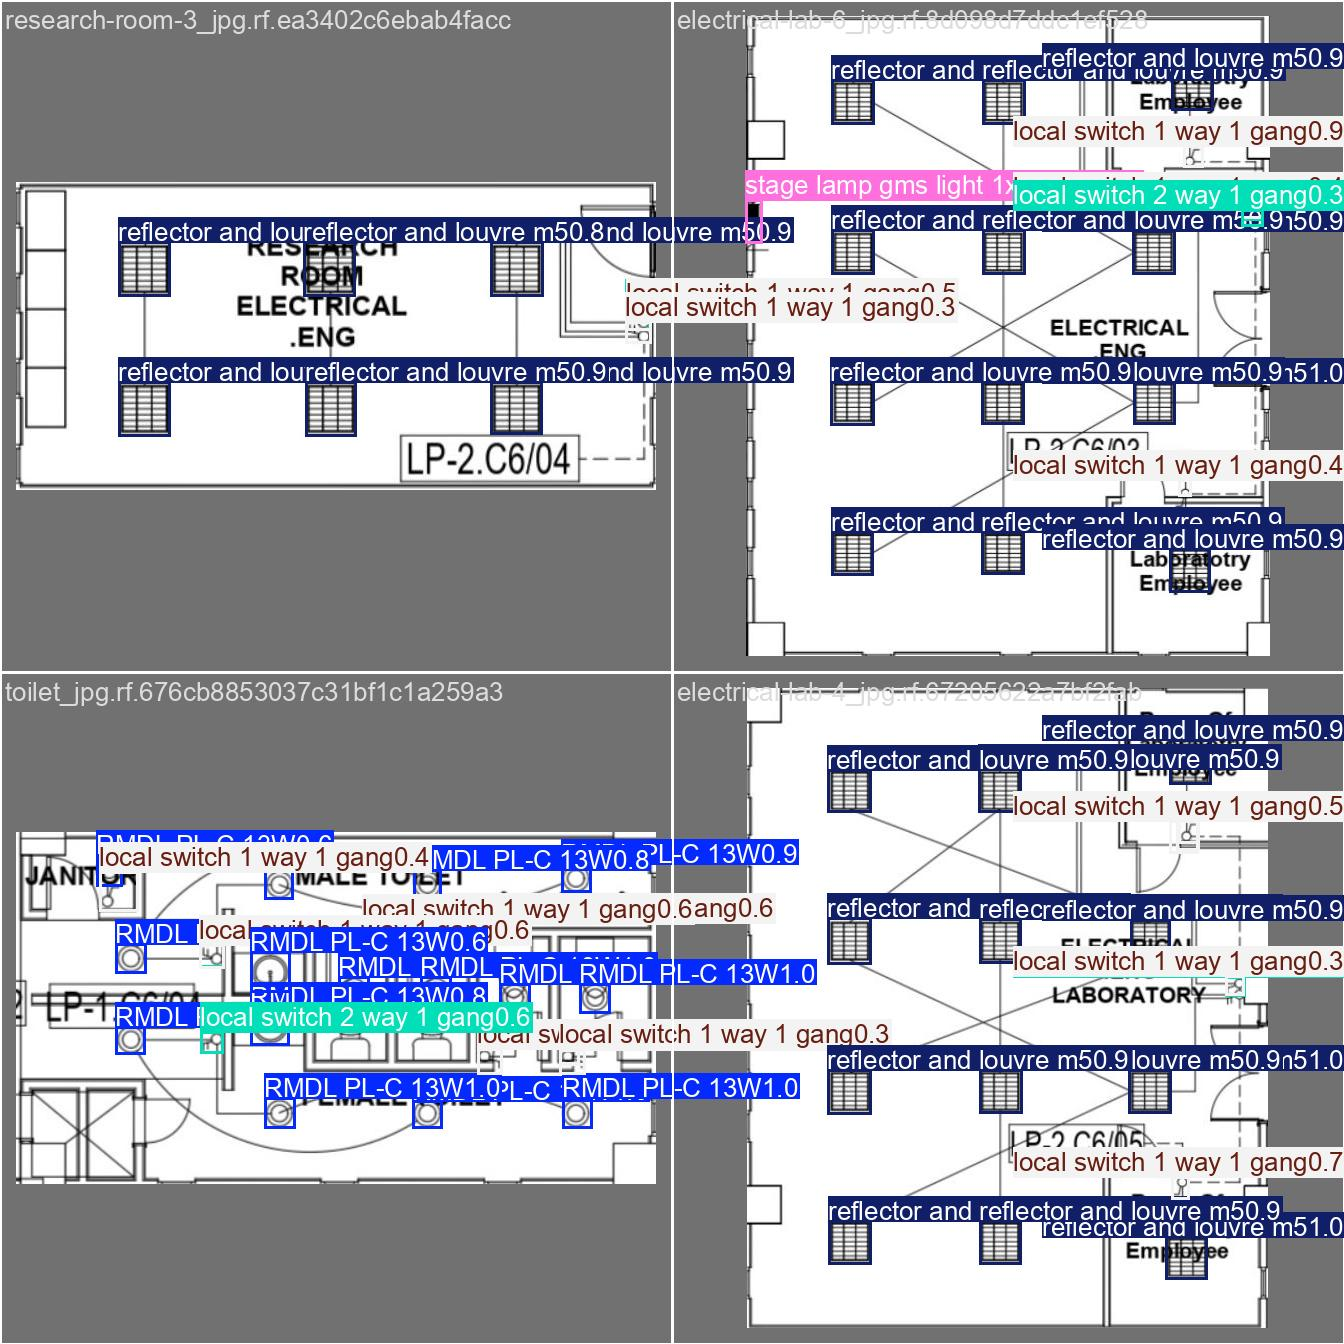

In [ ]:
%cd {HOME}
Image(filename=f'{HOME}/runs/detect/train/val_batch0_pred.jpg', width=600)

- Check mAP on Validation Dataset

In [ ]:
%cd {HOME}

!yolo task=detect mode=val model={HOME}/runs/detect/train/weights/best.pt data={dataset.location}/data.yaml

/content
Ultralytics 8.4.77 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1275.9±542.1 MB/s, size: 33.5 KB)
val: Scanning /content/Electrical-Simbol-6/valid/labels.cache... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 645.3Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 4.6it/s 0.2s
                   all          4         60      0.743      0.934      0.891      0.667
         RMDL PL-C 13W          1         13      0.828          1       0.99      0.825
local switch 1 way 1 gang          4         12      0.569      0.833      0.807      0.508
local switch 2 way 1 gang          4          5      0.599      0.903       0.77      0.472
reflector and louvre m5          3         30      0.977          1      0.995      0.865
Speed: 1.1ms preprocess, 1

## Test inference on Custom Yolo V8 Model
- trained model located in `{HOME}/runs/detect/train/weights/best.pt`
- we will try to do inferencing using that model to detect test image in `{dataset.location}/test/images`

In [ ]:
%cd {HOME}
!yolo task=detect mode=predict model={HOME}/runs/detect/train/weights/best.pt conf=0.4 source={dataset.location}/test/images save=True

/content
Ultralytics 8.4.77 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs

image 1/2 /content/Electrical-Simbol-6/test/images/information-lab-4_jpg.rf.e2e512b25ec5338bb1cc05dafe527832.jpg: 640x640 2 local switch 1 way 1 gangs, 2 local switch 2 way 1 gangs, 12 reflector and louvre m5s, 17.2ms
image 2/2 /content/Electrical-Simbol-6/test/images/toilet-2_jpg.rf.fac4722c682286cffcdd6abb6d70068a.jpg: 384x640 13 RMDL PL-C 13Ws, 5 local switch 1 way 1 gangs, 2 local switch 2 way 1 gangs, 81.8ms
Speed: 3.8ms preprocess, 49.5ms inference, 13.6ms postprocess per image at shape (1, 3, 384, 640)
Results saved to /content/runs/detect/predict
💡 Learn more at https://docs.ultralytics.com/modes/predict


- Above command will generating detected image that located in `/content/runs/detect/`
- Show the detection image result using script below

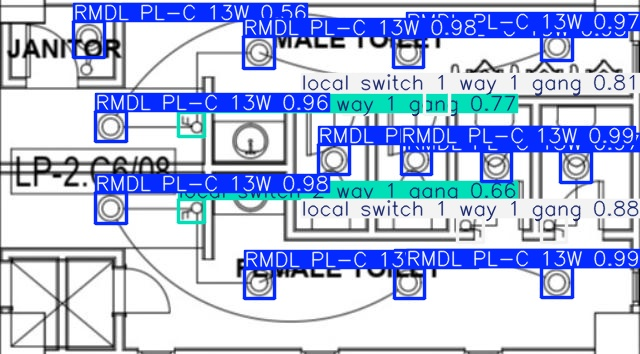

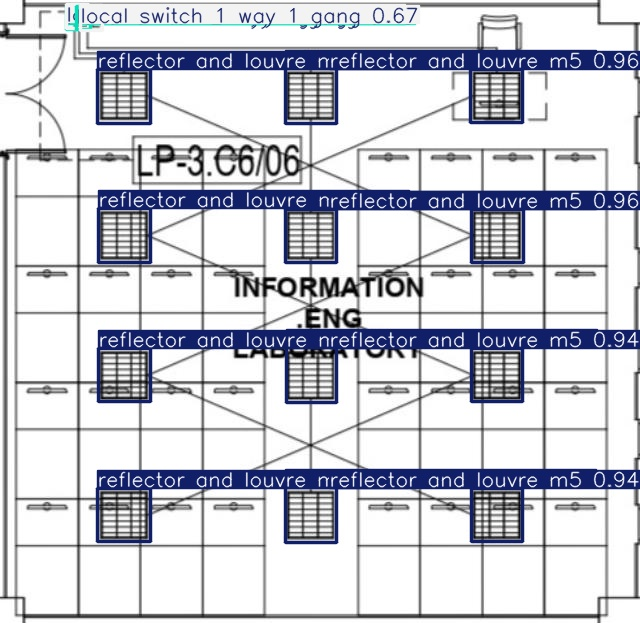

In [ ]:
import glob
from IPython.display import Image, display

# Define the base path where the folders are located
base_path = '/content/runs/detect/'

# List all directories that start with 'predict' in the base path
subfolders = [os.path.join(base_path, d) for d in os.listdir(base_path)
              if os.path.isdir(os.path.join(base_path, d)) and d.startswith('predict')]

# Find the latest folder by modification time
latest_folder = max(subfolders, key=os.path.getmtime)

image_paths = glob.glob(f'{latest_folder}/*.jpg')[:3]

# Display each image
for image_path in image_paths:
    display(Image(filename=image_path, width=320))
    print("\n")

## Export to ONNX
- To use Pytorch (`.pt`) model generated by Utralytic in OpenCV DNN, we will need to convert that into `ONNX` format

In [ ]:
# Export the model
from ultralytics import YOLO

model = YOLO(HOME + "/runs/detect/train/weights/best.pt")  # Load a model
model.export(format="onnx", opset=12, imgsz=[640, 640], simplify=True)

Ultralytics 8.4.77 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
Model summary (fused): 73 layers, 11,127,906 parameters, 0 gradients, 28.4 GFLOPs

PyTorch: starting from '/content/runs/detect/train/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 10, 8400) (21.5 MB)

ONNX: starting export with onnx 1.22.0 opset 12...
ONNX: slimming with onnxslim 0.1.94...
ONNX: export success ✅ 1.9s, saved as '/content/runs/detect/train/weights/best.onnx' (42.7 MB)

Export complete (2.9s)
Results saved to /content/runs/detect/train/weights/best.onnx
Predict:         yolo predict task=detect model=/content/runs/detect/train/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/runs/detect/train/weights/best.onnx imgsz=640 data=/content/Electrical-Simbol-6/data.yaml  
Visualize:       https://netron.app


'/content/runs/detect/train/weights/best.onnx'

In [ ]:
# Download Yolo Model.
from google.colab import files
import shutil

shutil.copy(HOME + "/runs/detect/train/weights/best.onnx", HOME + "/yolov8.onnx")
files.download(HOME + "/yolov8.onnx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


________________________________________________________________________

# Source
- https://github.com/roboflow/notebooks/blob/main/notebooks/train-yolov8-object-detection-on-custom-dataset.ipynb